In [1]:
!pip install cellpose
!pip install trackpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.4/213.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 69.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.5/26.5 MB 62.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.5/133.5 kB 6.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for trackpy: filename=trackpy-0.7-py3-none-any.whl size=130480 sha256=5bfa1bc61d38f726e2f2f6548f967dc1b3d2c64f8789e574aa3a31c6472a17b5
  Stored in directory: /root/.cache/pip/wheels/35/97/08/ded65bf12054e510a946f888e0bbaf9d698e449eb365791b94
Successfully built trackpy


In [2]:


import os
from tifffile import imread
from cellpose import models
from skimage.measure import regionprops
import pandas as pd
import trackpy as tp
import matplotlib.pyplot as plt
import numpy as np
import os
from tifffile import imread

In [3]:
import cellpose
print(cellpose.__file__)
from cellpose import models
print(dir(models))

/usr/local/lib/python3.12/dist-packages/cellpose/__init__.py
['CellposeModel', 'MODEL_DIR', 'MODEL_LIST_PATH', 'MODEL_NAMES', 'Path', 'Transformer', '_CPSAM_MODEL_URL', '_MODEL_DIR_DEFAULT', '_MODEL_DIR_ENV', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'assign_device', 'cache_CPSAM_model_path', 'cv2', 'dynamics', 'gaussian_filter', 'gc', 'get_user_models', 'logging', 'model_path', 'models_logger', 'normalize_default', 'np', 'os', 'plot', 'run_3D', 'run_net', 'time', 'torch', 'trange', 'transforms', 'utils']


In [4]:
# =========================
# 1. SELECT IMAGES MANUALLY
# =========================

import os
from skimage.io import imread
data_dir = "/kaggle/input/datasets/ebinjosephmannur/controlo-s1-p1-03022026" # change the input here

files = sorted([
    os.path.join(data_dir, f)
    for f in os.listdir(data_dir)
    if f.endswith(".tif")
])

print("Number of selected TIFF files:", len(files))

if len(files) == 0:
    raise ValueError("No TIFF images found")

images = []

for path in files:
    img = imread(path)

    if img.ndim == 3:
        img = img[..., 0]

    images.append(img)

print("Loaded images:", len(images))
print("Image shape:", images[0].shape)

Number of selected TIFF files: 246
Loaded images: 246
Image shape: (1024, 1536)


In [5]:
# =========================
# 2. SEGMENTATION (CELLPOSE)
# =========================

from cellpose import models

model = models.CellposeModel(gpu=True)

masks, flows, styles = model.eval(
    images,
    diameter=None
)

print("Segmentation complete")
# =========================
# MANUAL CELL SELECTION
# =========================

from skimage.measure import regionprops
import numpy as np

first_mask = masks[0]
props = regionprops(first_mask)

# Get centroids and areas
centroids = np.array([prop.centroid[::-1] for prop in props])  # (x, y)
areas = np.array([prop.area for prop in props])

# Select 30 largest cells
top_indices = np.argsort(areas)[-30:]

selected_centroids = centroids[top_indices]

print("Selected 30 centroids:", selected_centroids)

from scipy.spatial import distance

tracked_cells = []

tracked_cells.append(selected_centroids)

for i in range(1, len(masks)):
    props = regionprops(masks[i])
    centroids = np.array([prop.centroid[::-1] for prop in props])

    previous_centroids = tracked_cells[-1]
    new_centroids = []

    for prev in previous_centroids:
        if len(centroids) == 0:
            continue

        dists = distance.cdist([prev], centroids)
        nearest_idx = np.argmin(dists)

        new_centroids.append(centroids[nearest_idx])

    tracked_cells.append(np.array(new_centroids))

print("Tracking complete")

100%|██████████| 1.15G/1.15G [00:04<00:00, 292MB/s]


Segmentation complete
Selected 30 centroids: [[ 577.55398911  391.45145787]
 [1311.37711729  327.23106424]
 [1305.44950621  753.1041733 ]
 [ 684.68853503  717.3111465 ]
 [1175.84475173  159.82966688]
 [1419.99280125  825.91048513]
 [1068.72545341  173.73389619]
 [1340.15554882  130.91085506]
 [ 263.14560192  733.16001201]
 [ 289.29619727  372.72073678]
 [1325.50453084  963.115171  ]
 [1175.94919633  431.96182549]
 [ 726.77231121  290.30892449]
 [1316.70539538  414.88752498]
 [1043.54703742  768.07744283]
 [ 640.34927984  521.80092593]
 [ 306.88637532  139.53984576]
 [1090.11388535  238.95159236]
 [ 732.18644068  582.52444117]
 [ 444.57506735  921.45309821]
 [1226.68935343   70.23821099]
 [ 978.55853895  295.52177068]
 [ 701.45629665  202.98073682]
 [ 559.95646974  297.12676393]
 [ 769.99187181  145.01927543]
 [ 315.16685559  616.65041941]
 [ 269.87967264   92.06724176]
 [ 192.15830031  701.64464993]
 [1092.46848739  592.79965623]
 [1059.19840406  424.13946318]]
Tracking complete


In [6]:
# =========================
# 3. EXTRACT CENTROIDS
# =========================



max_distance = 50

data = []

current_positions = selected_centroids.copy()

for frame_idx, frame in enumerate(masks):
    props = regionprops(frame)

    # Get all centroids in current frame
    centroids = np.array([prop.centroid[::-1] for prop in props])  # (x, y)

    new_positions = current_positions.copy()

    for i, ref_point in enumerate(current_positions):

        if len(centroids) == 0:
            continue

        # Compute distances
        dists = np.linalg.norm(centroids - ref_point, axis=1)

        best_idx = np.argmin(dists)
        min_dist = dists[best_idx]

        if min_dist < max_distance:
            best_match = centroids[best_idx]

            data.append([frame_idx, best_match[0], best_match[1], i])

            new_positions[i] = best_match
        else:
            # If no match found → keep previous position
            new_positions[i] = ref_point

    current_positions = new_positions

df = pd.DataFrame(data, columns=['frame', 'x', 'y', 'cell_id'])

print(df.head())
print(df['frame'].value_counts())

   frame            x           y  cell_id
0      0   577.553989  391.451458        0
1      0  1311.377117  327.231064        1
2      0  1305.449506  753.104173        2
3      0   684.688535  717.311146        3
4      0  1175.844752  159.829667        4
frame
0      30
1      30
2      30
3      30
4      30
       ..
220    28
224    28
235    28
237    28
238    28
Name: count, Length: 246, dtype: int64


In [7]:

# =========================
# 4. TRACKING (TRACKPY)
# =========================

import pandas as pd
import trackpy as tp

# df must contain: frame, x, y (from your previous step)
# Example columns: ['frame', 'x', 'y']

# Copy data
t = df.copy()

# Ensure correct column names for TrackPy
t.rename(columns={'frame': 'frame', 'x': 'x', 'y': 'y'}, inplace=True)

# Track particles across frames
# search_range: max movement between frames (adjust based on your data)
# memory: number of frames a particle can disappear and still be linked
linked = tp.link_df(t, search_range=50, memory=3)

print("Tracking complete")
print(linked.head())

# =========================
# FILTER SHORT TRACKS
# =========================

# Keep only trajectories that last more than 10 frames
filtered = tp.filter_stubs(linked, threshold=10)

print("Filtered tracks:")
print(filtered.head())

# =========================
# FRAME RATE (1 frame = 1 minute)
# =========================

frame_rate_min = 1  # minutes per frame

filtered['time_min'] = filtered['frame'] * frame_rate_min

# =========================
# 5. PIXEL → MICROMETER CONVERSION
# =========================

# Physical size of image (µm)
image_width_um = 1335.69
image_height_um = 890.46

# Pixel dimensions
image_height_px, image_width_px = images[0].shape

# Conversion factors
pixel_to_um_x = image_width_um / image_width_px
pixel_to_um_y = image_height_um / image_height_px

print("Pixel size (µm):", pixel_to_um_x, pixel_to_um_y)

# Rename ID column
t = df.rename(columns={'cell_id': 'particle'})

# Sort
t = t.sort_values(['particle', 'frame'])

# Convert to micrometers
t['x_um'] = t['x'] * pixel_to_um_x
t['y_um'] = t['y'] * pixel_to_um_y

# Normalize trajectories
t['x0'] = t.groupby('particle')['x_um'].transform('first')
t['y0'] = t.groupby('particle')['y_um'].transform('first')

t['x_rel'] = t['x_um'] - t['x0']
t['y_rel'] = t['y_um'] - t['y0']

Frame 245: 29 trajectories present.
Tracking complete
   frame            x           y  cell_id  particle
0      0   577.553989  391.451458        0         0
1      0  1311.377117  327.231064        1         1
2      0  1305.449506  753.104173        2         2
3      0   684.688535  717.311146        3         3
4      0  1175.844752  159.829667        4         4
Filtered tracks:
       frame            x           y  cell_id  particle
frame                                                   
0          0   577.553989  391.451458        0         0
0          0  1311.377117  327.231064        1         1
0          0  1305.449506  753.104173        2         2
0          0   684.688535  717.311146        3         3
0          0  1175.844752  159.829667        4         4
Pixel size (µm): 0.86958984375 0.86958984375


    particle  mean_velocity_um_per_min
0          0                  2.011501
1          1                  1.484269
2          2                  3.554537
3          3                  2.626394
4          4                  3.196238
5          5                  1.938857
6          6                  3.169239
7          7                  2.621115
8          8                  2.110913
9          9                  3.767262
10        10                  1.799707
11        11                  2.194469
12        12                  1.878400
13        13                  2.918492
14        14                  2.784978
15        15                  3.591679
16        16                  2.255825
17        17                  2.794219
18        18                  2.349874
19        19                  3.256824
20        20                  2.369053
21        21                  1.758222
22        22                  3.256168
23        23                  2.271690
24        24             

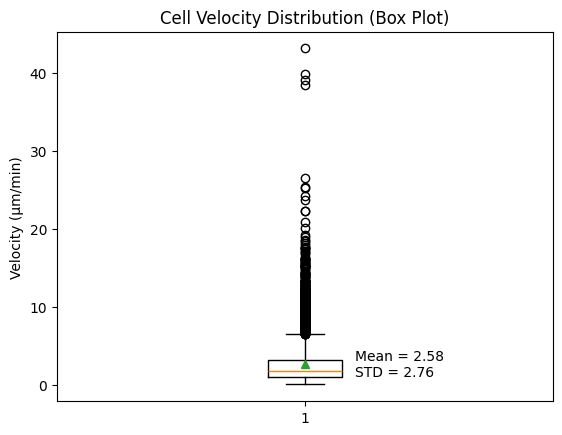

In [8]:
import numpy as np

# Ensure time column exists
t['time_min'] = t['frame'] * 1  # 1 frame = 1 minute

# Sort data
t = t.sort_values(['particle', 'frame'])

# Compute differences
t['dx'] = t.groupby('particle')['x_um'].diff()
t['dy'] = t.groupby('particle')['y_um'].diff()
t['dt'] = t.groupby('particle')['time_min'].diff()

# Velocity (µm/min)
t['velocity_um_per_min'] = np.sqrt(t['dx']**2 + t['dy']**2) / t['dt']

# Remove NaNs (first frame)
t_clean = t.dropna(subset=['velocity_um_per_min'])

# Mean velocity per cell
cell_velocity = t_clean.groupby('particle')['velocity_um_per_min'].mean()

# Convert to DataFrame (better for OriginPro)
cell_velocity_df = cell_velocity.reset_index()
cell_velocity_df.columns = ['particle', 'mean_velocity_um_per_min']

# Save for OriginPro
cell_velocity_df.to_csv("cell_velocity_data.csv", index=False)

print(cell_velocity_df)
import matplotlib.pyplot as plt
import numpy as np

# =========================
# BOX PLOT: VELOCITY DISTRIBUTION
# =========================

# Use cleaned data
velocities = t_clean['velocity_um_per_min']

# Compute stats
mean_vel = velocities.mean()
std_vel = velocities.std()

plt.figure()

# Box plot
plt.boxplot(velocities, vert=True, showmeans=True)

# Add mean ± std as text
plt.text(1.1, mean_vel, f"Mean = {mean_vel:.2f}\nSTD = {std_vel:.2f}",
         va='center')

plt.ylabel("Velocity (µm/min)")
plt.title("Cell Velocity Distribution (Box Plot)")

plt.show()

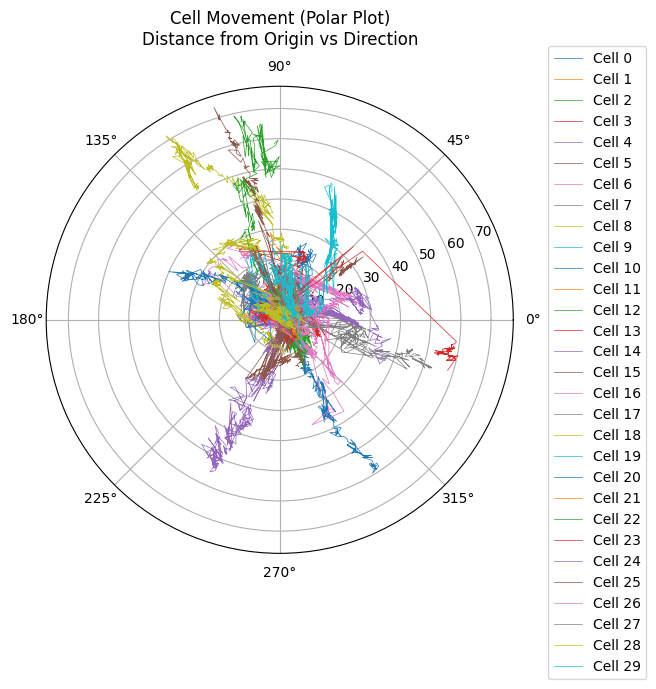

In [9]:
# =========================
# 6. POLAR GRAPH
# =========================

import numpy as np
import matplotlib.pyplot as plt

# Distance from origin (µm)
t['distance_um'] = np.sqrt(t['x_rel']**2 + t['y_rel']**2)

# Direction (angle in radians)
t['angle'] = np.arctan2(t['y_rel'], t['x_rel'])
t['angle_deg'] = np.degrees(t['angle'])

# Create polar plot
plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

for p in t['particle'].unique():
    track = t[t['particle'] == p]
    
    ax.plot(track['angle'], track['distance_um'],
            linewidth=0.5, label=f"Cell {p}")

# ✅ FIX: Move title away from plot (no overlap at 90°)
ax.set_title("Cell Movement (Polar Plot)\nDistance from Origin vs Direction",
             pad=30)  # <-- key fix

# Optional: improve layout
plt.tight_layout()

# Legend
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.show()

# =========================
# EXPORT DATA
# =========================

polar_data = t[['particle', 'frame', 'angle', 'distance_um']]
polar_data.to_csv("polar_plot_data.csv", index=False)

# =========================
# BAR CHART: MEAN VELOCITY PER CELL
# =========================

# Compute mean velocity per particle
mean_velocity = t.groupby('particle')['velocity_um_per_min'].mean()

# Optional: export velocity data
mean_velocity.to_csv("mean_velocity_per_cell.csv", header=True)

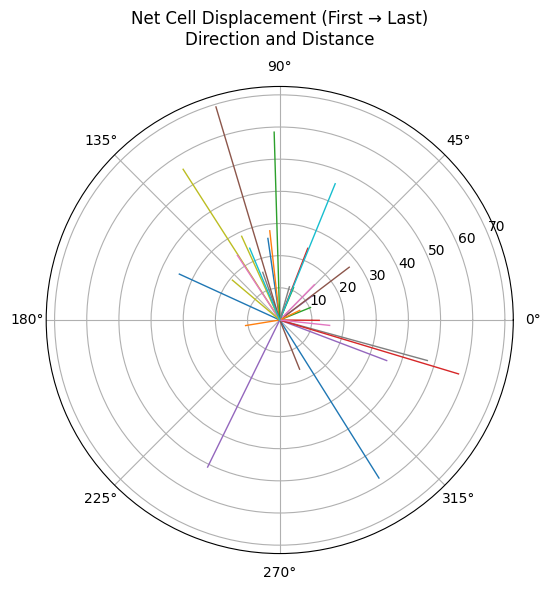

In [10]:
# =========================
# POLAR GRAPH (FIRST → LAST)
# =========================

import numpy as np
import matplotlib.pyplot as plt

first_last_data = []

plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

for p in t['particle'].unique():
    track = t[t['particle'] == p].sort_values('frame')
    
    if len(track) < 2:
        continue  # skip short tracks

    # First and last positions
    x0, y0 = track.iloc[0][['x_rel', 'y_rel']]
    x1, y1 = track.iloc[-1][['x_rel', 'y_rel']]

    # Displacement
    dx = x1 - x0
    dy = y1 - y0

    # Polar coordinates
    distance = np.sqrt(dx**2 + dy**2)
    angle = np.arctan2(dy, dx)
    angle_deg = np.degrees(angle)

    # Store data
    first_last_data.append([p, angle, angle_deg, distance])

    # Plot as single vector (from 0 to distance)
    ax.plot([angle, angle], [0, distance],
            linewidth=1)

# Title fix
ax.set_title("Net Cell Displacement (First → Last)\nDirection and Distance",
             pad=30)

plt.tight_layout()
plt.show()

# =========================
# EXPORT DATA
# =========================



In [11]:
import pandas as pd

first_last_df = pd.DataFrame(first_last_data,
                             columns=['particle', 'angle_rad', 'angle_deg', 'distance_um'])

first_last_df.to_csv("polar_first_last_data.csv", index=False)

print(first_last_df.head())

   particle  angle_rad  angle_deg  distance_um
0         0   1.714973  98.260702    25.630464
1         1   1.682244  96.385501    27.908991
2         2   0.385646  22.095868    10.323475
3         3   1.198269  68.655769    23.929459
4         4   0.637875  36.547531    12.681452


In [12]:
import numpy as np
import pandas as pd

# Ensure distance and angle are computed
t['distance_um'] = np.sqrt(t['x_rel']**2 + t['y_rel']**2)
t['angle'] = np.arctan2(t['y_rel'], t['x_rel'])
t['angle_deg'] = np.degrees(t['angle'])

# Sort for proper trajectory plotting
t_sorted = t.sort_values(['particle', 'frame'])

# Select clean columns
polar_data = t_sorted[['particle', 'frame', 'angle', 'angle_deg', 'distance_um']]

# Save for external software (OriginPro, MATLAB, etc.)
polar_data.to_csv("polar_plot_data.csv", index=False)

print(polar_data.head())

     particle  frame     angle  angle_deg  distance_um
0           0      0  0.000000   0.000000     0.000000
30          0      1 -0.917384 -52.562244     1.737126
60          0      2 -1.022391 -58.578681     1.080996
90          0      3  1.477875  84.676017     0.746522
120         0      4 -1.097705 -62.893857     1.931297


    particle  directedness
0          0     -0.020294
1          1     -0.007210
2          2      0.017101
3          3      0.022975
4          4      0.009640
5          5      0.050382
6          6      0.029034
7          7      0.046563
8          8     -0.100618
9          9      0.023454
10        10     -0.001919
11        11     -0.007535
12        12     -0.001484
13        13     -0.004353
14        14      0.053305
15        15      0.019385
16        16     -0.028072
17        17      0.094626
18        18      0.006706
19        19      0.026129
20        20     -0.033905
21        21      0.009985
22        22     -0.006128
23        23     -0.028257
24        24     -0.044959
25        25     -0.029003
26        26      0.031634
27        27     -0.004109
28        28     -0.031954
29        29     -0.014339


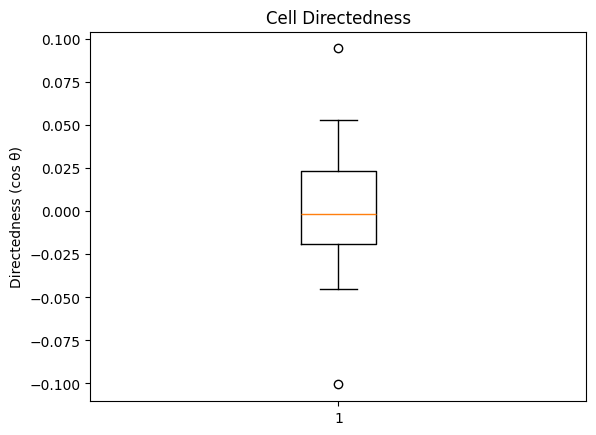

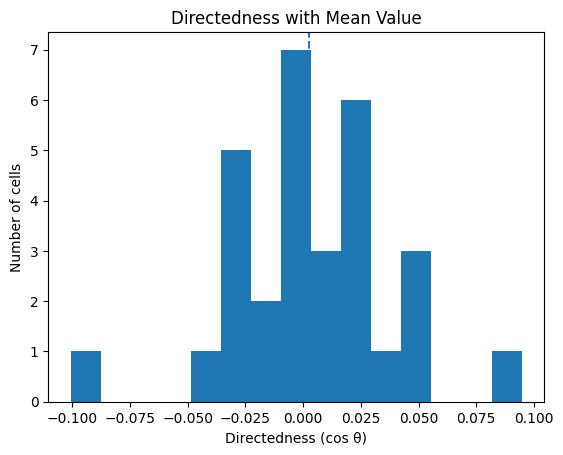

In [13]:
import numpy as np
import pandas as pd

def directedness(track, field_vector):
    track = track.sort_values('frame')

    dx = track['x_um'].diff().dropna()
    dy = track['y_um'].diff().dropna()

    if len(dx) == 0:
        return np.nan

    vectors = np.column_stack((dx.values, dy.values))

    norm_f = np.linalg.norm(field_vector)
    if norm_f == 0:
        return np.nan

    field_norm = field_vector / norm_f

    projections = []

    for v in vectors:
        norm = np.linalg.norm(v)
        if norm > 0:
            v_norm = v / norm
            projections.append(np.dot(v_norm, field_norm))

    if len(projections) == 0:
        return np.nan

    return np.mean(projections)

# -------------------------
# COMPUTE FOR EACH CELL
# -------------------------

field_vector = np.array([1, 0])  # change if needed

directedness_list = []

for p in t['particle'].unique():
    track = t[t['particle'] == p]
    d = directedness(track, field_vector)

    directedness_list.append([p, d])

# Convert to DataFrame
dir_df = pd.DataFrame(directedness_list, columns=['particle', 'directedness'])

# Remove NaNs
dir_df_clean = dir_df.dropna()

# Save for OriginPro
dir_df_clean.to_csv("directedness_per_cell.csv", index=False)
values = dir_df_clean['directedness'].values
print(dir_df_clean)
mean = dir_df_clean['directedness'].mean()
std = dir_df_clean['directedness'].std()
plt.figure()

plt.boxplot(values)

plt.ylabel("Directedness (cos θ)")
plt.title("Cell Directedness")

plt.show()

# -------------------------
# HISTOGRAM WITH MEAN
# -------------------------

plt.figure()
plt.hist(values, bins=15)

plt.axvline(np.nanmean(values), linestyle='--')

plt.xlabel("Directedness (cos θ)")
plt.ylabel("Number of cells")
plt.title("Directedness with Mean Value")

plt.show()

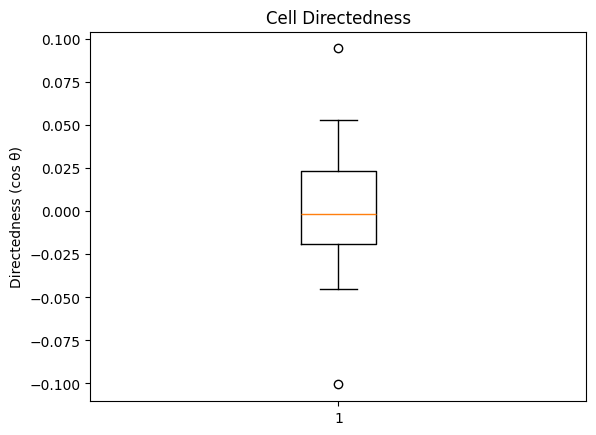

In [14]:
# Save for OriginPro
dir_df_clean.to_csv("directedness_per_cell.csv", index=False)
values = dir_df_clean['directedness'].values

mean = dir_df_clean['directedness'].mean()
std = dir_df_clean['directedness'].std()
plt.figure()

plt.boxplot(values)

plt.ylabel("Directedness (cos θ)")
plt.title("Cell Directedness")

plt.show()